In [113]:
# 1. configuration

from pathlib import Path
from datetime import date

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

PROJECT_DIR = Path.home() / "tsmom_project"

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
EXTERNAL_DIR = PROJECT_DIR / "data" / "external"

START_DATE = "2000-01-01"
END_DATE = "2026-11-16"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

print("Project directory:", PROJECT_DIR)
print("Data collection date:", date.today())

Project directory: /Users/augustinenguyen/tsmom_project
Data collection date: 2026-11-17


In [114]:
# 2. Define the preliminary investment universe

universe = {
    "Equity": ["SPY", "QQQ", "IWM", "EWJ", "VGK"],
    "Fixed Income": ["TLT", "IEF", "SHY"],
    "Commodities": ["GLD", "SLV", "DBC", "USO"],
    "Currencies": ["UUP", "FXE", "FXY"]
}

tickers = [
    ticker
    for asset_class in universe.values()
    for ticker in asset_class
]

print(f"Number of candidate instruments: {len(tickers)}")
print(tickers)

Number of candidate instruments: 15
['SPY', 'QQQ', 'IWM', 'EWJ', 'VGK', 'TLT', 'IEF', 'SHY', 'GLD', 'SLV', 'DBC', 'USO', 'UUP', 'FXE', 'FXY']


In [115]:
# 3. Download historical ETF data

START_DATE = "2000-01-01"
END_DATE = "2026-11-16"  # only in yfinance

raw_data = {}
download_errors = {}

for ticker in tickers:
    print(f"Downloading {ticker}...")

    try:
        df = yf.download(
            ticker,
            start=START_DATE,
            end=END_DATE,
            interval="1d",
            auto_adjust=False,
            actions=True,
            repair=True,
            progress=False,
            threads=False
        )

        if df.empty:
            download_errors[ticker] = "No data returned"
            continue

        # Handle possible MultiIndex columns
        if isinstance(df.columns, pd.MultiIndex):
            df.columns = df.columns.get_level_values(0)

        df = df[~df.index.duplicated(keep="first")]
        df = df.sort_index()

        raw_data[ticker] = df

        # Preserve the original downloaded data
        df.to_parquet(RAW_DIR / f"{ticker}.parquet")

        print(f"  {len(df):,} observations | "
              f"{df.index.min().date()} to {df.index.max().date()}")

    except Exception as e:
        download_errors[ticker] = str(e)
        print(f"  ERROR: {e}")

print("\nDownload completed.")
print(f"Successful: {len(raw_data)}")
print(f"Failed: {len(download_errors)}")

  6,758 observations | 2000-01-03 to 2026-11-13
  6,758 observations | 2000-01-03 to 2026-11-13
  6,657 observations | 2000-05-26 to 2026-11-13
  6,758 observations | 2000-01-03 to 2026-11-13
  5,456 observations | 2005-03-10 to 2026-11-13
  6,114 observations | 2002-07-30 to 2026-11-13
  6,114 observations | 2002-07-30 to 2026-11-13
  6,114 observations | 2002-07-30 to 2026-11-13
  5,532 observations | 2004-11-18 to 2026-11-13
  5,170 observations | 2006-04-28 to 2026-11-13
  5,227 observations | 2006-02-06 to 2026-11-13
  5,183 observations | 2006-04-10 to 2026-11-13
  4,960 observations | 2007-03-01 to 2026-11-13
  5,264 observations | 2005-12-12 to 2026-11-13
  4,971 observations | 2007-02-13 to 2026-11-13

Download completed.
Successful: 15
Failed: 0


In [116]:
# 4. Historical coverage report

coverage = []

for ticker, df in raw_data.items():
    coverage.append({
        "Ticker": ticker,
        "First Date": df.index.min().date(),
        "Last Date": df.index.max().date(),
        "Observations": len(df),
        "Missing Close (%)": df["Close"].isna().mean() * 100,
        "Missing Adj Close (%)": df["Adj Close"].isna().mean() * 100,
        "Missing OHLC (%)": (
            df[["Open", "High", "Low", "Close"]]
            .isna().any(axis=1).mean() * 100
        )
    })

coverage_df = pd.DataFrame(coverage).set_index("Ticker")

display(coverage_df.round(2))

,First Date,Last Date,Observations,Missing Close (%),Missing Adj Close (%),Missing OHLC (%)
Ticker,,,,,,
SPY,2000-01-03,2026-11-13,6758,0.0,0.0,0.0
QQQ,2000-01-03,2026-11-13,6758,0.0,0.0,0.0
IWM,2000-05-26,2026-11-13,6657,0.0,0.0,0.0
EWJ,2000-01-03,2026-11-13,6758,0.0,0.0,0.0
VGK,2005-03-10,2026-11-13,5456,0.0,0.0,0.0
TLT,2002-07-30,2026-11-13,6114,0.0,0.0,0.0
IEF,2002-07-30,2026-11-13,6114,0.0,0.0,0.0
SHY,2002-07-30,2026-11-13,6114,0.0,0.0,0.0
GLD,2004-11-18,2026-11-13,5532,0.0,0.0,0.0


In [117]:
import pandas as pd

#data availability
summary_list = []
for ticker, df in raw_data.items():
    summary_list.append({
        "ETF": ticker,
        "Start Date": df.index.min(),
        "End Date": df.index.max(),
        "Total Observations": len(df)
    })

availability_df = pd.DataFrame(summary_list)
print(availability_df.to_string(index=False))

ETF Start Date   End Date  Total Observations
SPY 2000-01-03 2026-11-13                6758
QQQ 2000-01-03 2026-11-13                6758
IWM 2000-05-26 2026-11-13                6657
EWJ 2000-01-03 2026-11-13                6758
VGK 2005-03-10 2026-11-13                5456
TLT 2002-07-30 2026-11-13                6114
IEF 2002-07-30 2026-11-13                6114
SHY 2002-07-30 2026-11-13                6114
GLD 2004-11-18 2026-11-13                5532
SLV 2006-04-28 2026-11-13                5170
DBC 2006-02-06 2026-11-13                5227
USO 2006-04-10 2026-11-13                5183
UUP 2007-03-01 2026-11-13                4960
FXE 2005-12-12 2026-11-13                5264
FXY 2007-02-13 2026-11-13                4971


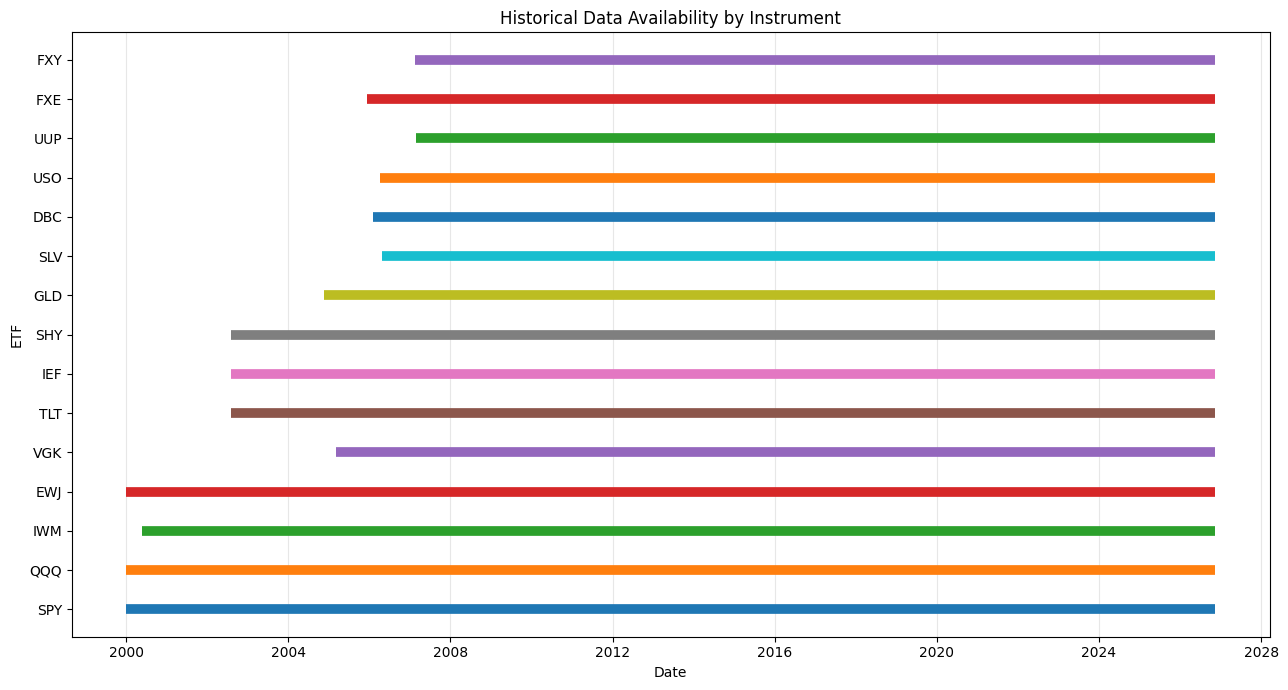

In [118]:
# 5.data availability

fig, ax = plt.subplots(figsize=(13, 7))

for ticker, df in raw_data.items():
    ax.plot(
        [df.index.min(), df.index.max()],
        [ticker, ticker],
        linewidth=7,
        solid_capstyle="butt"
    )

ax.set_title("Historical Data Availability by Instrument")
ax.set_xlabel("Date")
ax.set_ylabel("ETF")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [119]:
# 6.data integrity audit

integrity_results = []

for ticker, df in raw_data.items():

    required = ["Open", "High", "Low", "Close", "Adj Close", "Volume"]
    available = [c for c in required if c in df.columns]

    prices = df[available]

    #price consistency
    invalid_prices = (
        (df["High"] < df["Low"]) |
        (df["Open"] > df["High"]) |
        (df["Open"] < df["Low"]) |
        (df["Close"] > df["High"]) |
        (df["Close"] < df["Low"])
    )

    #adjusted close daily returns
    returns = df["Adj Close"].pct_change().dropna()

    integrity_results.append({
        "Ticker": ticker,
        "Missing OHLC (%)": (
            df[["Open", "High", "Low", "Close"]]
            .isna().any(axis=1).mean() * 100
        ),
        "Invalid OHLC rows": invalid_prices.sum(),
        "Zero-volume rows": (df["Volume"] == 0).sum(),
        "Missing volume (%)": df["Volume"].isna().mean() * 100,
        "Largest daily gain (%)": returns.max() * 100,
        "Largest daily loss (%)": returns.min() * 100,
        "Returns above 10%": (returns > 0.10).sum(),
        "Returns below -10%": (returns < -0.10).sum()
    })

integrity_df = pd.DataFrame(integrity_results).set_index("Ticker")

display(integrity_df.round(2))

,Missing OHLC (%),Invalid OHLC rows,Zero-volume rows,Missing volume (%),Largest daily gain (%),Largest daily loss (%),Returns above 10%,Returns below -10%
Ticker,,,,,,,,
SPY,0.0,0,0,0.0,14.52,-10.94,3,1
QQQ,0.0,0,0,0.0,16.84,-11.98,9,1
IWM,0.0,0,0,0.0,9.15,-13.27,0,3
EWJ,0.0,0,0,0.0,15.82,-10.41,2,1
VGK,0.0,0,0,0.0,14.19,-11.78,2,5
TLT,0.0,0,0,0.0,7.52,-6.67,0,0
IEF,0.0,0,0,0.0,3.43,-2.51,0,0
SHY,0.0,0,0,0.0,1.00,-0.66,0,0
GLD,0.0,0,0,0.0,11.29,-10.27,1,1


In [120]:
# 7.missing observations against SPY trading dates

reference_dates = raw_data["SPY"].index

calendar_results = []

for ticker, df in raw_data.items():

    expected_dates = reference_dates[
        (reference_dates >= df.index.min()) &
        (reference_dates <= df.index.max())
    ]

    missing_dates = expected_dates.difference(df.index)

    calendar_results.append({
        "Ticker": ticker,
        "Expected observations": len(expected_dates),
        "Actual observations": len(df),
        "Missing trading dates": len(missing_dates),
        "Missing (%)": len(missing_dates) / len(expected_dates) * 100
    })

calendar_df = pd.DataFrame(calendar_results).set_index("Ticker")

display(calendar_df.round(2))

,Expected observations,Actual observations,Missing trading dates,Missing (%)
Ticker,,,,
SPY,6758,6758,0,0.0
QQQ,6758,6758,0,0.0
IWM,6657,6657,0,0.0
EWJ,6758,6758,0,0.0
VGK,5456,5456,0,0.0
TLT,6114,6114,0,0.0
IEF,6114,6114,0,0.0
SHY,6114,6114,0,0.0
GLD,5532,5532,0,0.0


In [121]:
print("Daily returns:", returns_df.shape)
print("Adjusted close:", adj_close_df.shape)

print("First date:", returns_df.index.min())
print("Last date:", returns_df.index.max())

print("Missing returns:")
display(returns_df.isna().sum())

Daily returns: (4959, 15)
Adjusted close: (4959, 15)
First date: 2007-03-02 00:00:00
Last date: 2026-11-13 00:00:00
Missing returns:


SPY    0
QQQ    0
IWM    0
EWJ    0
VGK    0
TLT    0
IEF    0
SHY    0
GLD    0
SLV    0
DBC    0
USO    0
UUP    0
FXE    0
FXY    0
dtype: int64

In [122]:
#missing UUP daily return

missing_uup_date = daily_returns["UUP"].index[
    daily_returns["UUP"].isna()
]

for dt in missing_uup_date:
    display(raw_data["UUP"].loc[
        dt - pd.Timedelta(days=3):
        dt + pd.Timedelta(days=3)
    ])

Price,Adj Close,Capital Gains,Close,Dividends,High,Low,Open,Repaired?,Stock Splits,Volume
Date,,,,,,,,,,
2007-03-01,20.549210,0.0,24.969999,0.0,25.00,24.930000,24.93,False,0.0,4600
2007-03-02,20.540976,0.0,24.959999,0.0,25.26,24.950001,25.02,False,0.0,2400


In [123]:
# # 8.common historical sample (Updated)

first_dates = {
    ticker: df.index.min()
    for ticker, df in raw_data.items()
}

last_dates = {
    ticker: df.index.max()
    for ticker, df in raw_data.items()
}

#latest start date among all instruments (UUP on 2007-03-01)
latest_start = max(first_dates.values())

# Since UUP's first day (2007-03-01) yields a NaN return, 
# we shift common_start to the *next* trading day (2007-03-02) 
# so that all assets have valid returns from day one.

trading_dates = raw_data["SPY"].index
latest_start_idx = trading_dates.get_loc(latest_start)
common_start = trading_dates[latest_start_idx + 1]

common_end = min(last_dates.values())

common_dates = raw_data["SPY"].loc[
    common_start:common_end
].index

print("Common sample starts:", common_start.date())
print("Common sample ends:", common_end.date())
print("SPY trading observations:", len(common_dates))

Common sample starts: 2007-03-02
Common sample ends: 2026-11-13
SPY trading observations: 4959


In [124]:
# 9.save initial data

coverage_df.to_csv(RAW_DIR / "coverage_report.csv")
integrity_df.to_csv(RAW_DIR / "integrity_report.csv")
calendar_df.to_csv(RAW_DIR / "calendar_report.csv")

print("Audit reports saved.")

Audit reports saved.


In [125]:
# 10.extreme adjusted-price returns

extreme_events = []

for ticker, df in raw_data.items():

    returns = df["Adj Close"].pct_change()

    extreme_dates = returns[
        (returns > 0.10) | (returns < -0.10)
    ].index

    for dt in extreme_dates:
        extreme_events.append({
            "Ticker": ticker,
            "Date": dt.date(),
            "Adjusted return (%)": returns.loc[dt] * 100,
            "Open": df.loc[dt, "Open"],
            "High": df.loc[dt, "High"],
            "Low": df.loc[dt, "Low"],
            "Close": df.loc[dt, "Close"],
            "Adj Close": df.loc[dt, "Adj Close"],
            "Volume": df.loc[dt, "Volume"]
        })

extreme_df = pd.DataFrame(extreme_events)

display(
    extreme_df.sort_values(
        "Adjusted return (%)",
        key=lambda x: x.abs(),
        ascending=False
    ).round(3)
)

,Ticker,Date,Adjusted return (%),Open,High,Low,Close,Adj Close,Volume
39,SLV,2026-01-30,-28.540,89.330,92.140,69.120,75.440,75.440,510687700
45,USO,2020-03-09,-25.315,54.560,58.400,52.000,52.160,52.160,19268563
53,USO,2020-04-21,-25.067,25.520,27.200,18.480,22.480,22.480,124913013
32,SLV,2008-10-10,-17.992,11.390,11.700,9.270,9.800,9.800,24731700
48,USO,2020-03-18,-17.513,40.480,41.440,34.320,37.680,37.680,23764250
7,QQQ,2001-01-03,16.842,52.188,65.250,52.156,62.438,52.657,118175700
50,USO,2020-04-02,16.667,36.640,45.360,36.000,40.880,40.880,40226725
17,EWJ,2008-10-13,15.822,34.640,37.920,34.600,37.480,27.178,14758900
40,SLV,2026-02-05,-15.774,68.230,70.520,65.510,66.690,66.690,170928000
51,USO,2020-04-03,15.460,45.600,48.160,43.520,47.200,47.200,28238825


In [126]:
# 11.inspect zero-volume observations

for ticker, df in raw_data.items():

    zero_volume = df[df["Volume"] == 0]

    if not zero_volume.empty:
        print(f"\n{ticker}:")
        display(zero_volume)


UUP:


Price,Adj Close,Capital Gains,Close,Dividends,High,Low,Open,Repaired?,Stock Splits,Volume
Date,,,,,,,,,,
2007-03-15,20.540976,0.0,24.959999,0.0,24.959999,24.959999,24.959999,False,0.0,0


In [127]:
# 12.inspect dividends and stock splits

corporate_actions = []

for ticker, df in raw_data.items():

    for dt, row in df.iterrows():

        dividend = row.get("Dividends", 0)
        split = row.get("Stock Splits", 0)

        if pd.notna(dividend) and dividend != 0:
            corporate_actions.append({
                "Ticker": ticker,
                "Date": dt.date(),
                "Action": "Dividend",
                "Value": dividend
            })

        if pd.notna(split) and split != 0:
            corporate_actions.append({
                "Ticker": ticker,
                "Date": dt.date(),
                "Action": "Stock Split",
                "Value": split
            })

corporate_actions_df = pd.DataFrame(corporate_actions)

display(corporate_actions_df.head(30))
print("Total corporate actions:", len(corporate_actions_df))

,Ticker,Date,Action,Value
0,SPY,2000-03-17,Dividend,0.371
1,SPY,2000-06-16,Dividend,0.348
2,SPY,2000-09-15,Dividend,0.375
3,SPY,2000-12-15,Dividend,0.411
4,SPY,2001-03-16,Dividend,0.316
5,SPY,2001-06-15,Dividend,0.346
6,SPY,2001-09-21,Dividend,0.369
7,SPY,2001-12-21,Dividend,0.393
8,SPY,2002-03-15,Dividend,0.331
9,SPY,2002-06-21,Dividend,0.353


Total corporate actions: 1396


In [128]:
# 13.adjusted OHLC and daily total returns

adjusted_ohlc = {}
daily_returns = {}

for ticker, df in raw_data.items():

    data = df.copy()

    # Adjustment factor
    adjustment_factor = data["Adj Close"] / data["Close"]

    # Adjust OHLC consistently
    for col in ["Open", "High", "Low", "Close"]:
        data[f"Adj_{col}"] = data[col] * adjustment_factor

    # Daily total returns
    data["Return"] = data["Adj Close"].pct_change()

    adjusted_ohlc[ticker] = data[
        ["Adj_Open", "Adj_High", "Adj_Low", "Adj_Close"]
    ].copy()

    daily_returns[ticker] = data["Return"].copy()

print("Adjusted OHLC and daily returns constructed.")

Adjusted OHLC and daily returns constructed.


In [141]:
# 14.panel datasets

returns_df = pd.DataFrame(daily_returns)
returns_df.index.name = "Date"

adj_close_df = pd.DataFrame({
    ticker: df["Adj Close"]
    for ticker, df in raw_data.items()
})

adj_ohlc_df = {
    ticker: adjusted_ohlc[ticker]
    for ticker in tickers
}

#limit to common sample
returns_df = returns_df.loc[common_start:common_end]
adj_close_df = adj_close_df.loc[common_start:common_end]

print("Returns shape:", returns_df.shape)
print("Adjusted close shape:", adj_close_df.shape)

display(returns_df.head())

Returns shape: (4959, 15)
Adjusted close shape: (4959, 15)


,SPY,QQQ,IWM,EWJ,VGK,TLT,IEF,SHY,GLD,SLV,DBC,USO,UUP,FXE,FXY
Date,,,,,,,,,,,,,,,
2007-03-02,-0.013095,-0.015070,-0.019892,-0.016338,-0.010232,0.005013,0.003241,0.001122,-0.032057,-0.048892,-0.009189,-0.004489,-0.000401,0.000682,0.006566
2007-03-05,-0.009519,-0.007769,-0.021988,-0.014533,-0.017229,0.001663,0.000599,0.000375,-0.012243,-0.025547,-0.014919,-0.027250,0.006410,-0.007576,0.006989
2007-03-06,0.017110,0.016607,0.027271,0.023876,0.027287,-0.002988,-0.001315,-0.000872,0.019387,0.027652,0.009414,0.014107,-0.000796,0.002672,-0.007403
2007-03-07,-0.001002,-0.003967,-0.003238,-0.002057,0.003858,0.003887,0.001796,0.000997,0.002338,0.000310,0.013788,0.019277,-0.003984,0.004415,0.005943
2007-03-08,0.008455,0.006795,0.007536,0.008935,0.005026,-0.000886,-0.000120,0.000000,0.002799,0.001163,0.001600,0.000000,0.004800,-0.003183,-0.009268


In [130]:
# 15.validate return construction

validation = []

for ticker in tickers:

    expected = raw_data[ticker]["Adj Close"].pct_change()
    calculated = daily_returns[ticker]

    difference = (expected - calculated).abs().max()

    validation.append({
        "Ticker": ticker,
        "Maximum calculation difference": difference,
        "Missing returns (%)": calculated.isna().mean() * 100
    })

validation_df = pd.DataFrame(validation).set_index("Ticker")

display(validation_df)

,Maximum calculation difference,Missing returns (%)
Ticker,,
SPY,0.0,0.014797
QQQ,0.0,0.014797
IWM,0.0,0.015022
EWJ,0.0,0.014797
VGK,0.0,0.018328
TLT,0.0,0.016356
IEF,0.0,0.016356
SHY,0.0,0.016356
GLD,0.0,0.018077


In [142]:
#missing UUP daily return

print("Missing values in dataset:")
print(returns_df["UUP"].isna().sum())

Missing values in dataset:
0


In [143]:
# 16.save processed data

returns_df.to_parquet(PROCESSED_DIR / "daily_returns.parquet")
adj_close_df.to_parquet(PROCESSED_DIR / "adjusted_close.parquet")

for ticker, df in adj_ohlc_df.items():
    df.to_parquet(PROCESSED_DIR / f"{ticker}_adjusted_ohlc.parquet")

print("Processed datasets saved.")

Processed datasets saved.
